In [1]:

# ============================================================
# Cell 1: Install required libraries for QLoRA fine-tuning
# ============================================================
# Purpose:
#   Install compatible dependencies for fine-tuning
#   a Clinical QA language model using QLoRA.
#
# Notes:
#   - Gradio and Diffusers are not required for training.
#   - vLLM and GPTQ will be handled in later notebooks.
#   - Keep Transformers and Hugging Face Hub compatible.
# ============================================================

# Remove conflicting libraries not used in this notebook
%pip uninstall -y gradio gradio-client diffusers

# Install training dependencies
%pip install -q \
    "transformers>=4.56.0,<4.58.0" \
    "trl==0.27.0" \
    "peft>=0.17.0,<0.19.0" \
    "datasets>=3.0.0,<5.0.0" \
    "accelerate>=1.0.0" \
    "bitsandbytes>=0.45.0" \
    "huggingface-hub>=0.34.0,<1.0" \
    "pandas==2.2.3" \
    "numpy==2.2.6" \
    "pyarrow==23.0.1" \
    "matplotlib" \
    "safetensors"


Found existing installation: gradio 6.31.0
Uninstalling gradio-6.31.0:
  Successfully uninstalled gradio-6.31.0
Found existing installation: gradio_client 2.7.2
Uninstalling gradio_client-2.7.2:
  Successfully uninstalled gradio_client-2.7.2
Found existing installation: diffusers 0.42.1
Uninstalling diffusers-0.42.1:
  Successfully uninstalled diffusers-0.42.1


In [2]:

# ============================================================
# Cell 2: Imports, GPU checks and reproducibility
# ============================================================

import os
import gc
import json
import time
import random
import shutil
import inspect

from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from datasets import Dataset, load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
)

from peft import LoraConfig, TaskType
from trl import SFTTrainer, SFTConfig

# Reproducibility seed used in Notebook 01.
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Verify that Colab provides a CUDA GPU.
assert torch.cuda.is_available(), (
    "CUDA GPU unavailable. Enable T4 GPU in Colab."
)

GPU_NAME = torch.cuda.get_device_name(0)

GPU_MEMORY_GB = (
    torch.cuda.get_device_properties(0).total_memory
    / (1024 ** 3)
)

print("GPU:", GPU_NAME)
print(f"Total GPU memory: {GPU_MEMORY_GB:.2f} GB")
print("PyTorch:", torch.__version__)

import transformers
import trl
import peft

print("Transformers:", transformers.__version__)
print("TRL:", trl.__version__)
print("PEFT:", peft.__version__)


GPU: NVIDIA A100-SXM4-40GB
Total GPU memory: 39.49 GB
PyTorch: 2.14.1+cu130
Transformers: 4.57.6
TRL: 0.27.0
PEFT: 0.18.1


In [3]:

# ============================================================
# Cell 3: Mount Drive and configure project directories
# ============================================================

from google.colab import drive

drive.mount("/content/drive")

# Same project directory used in Notebook 01.
PROJECT_DIR = Path(
    "/content/drive/MyDrive/clinical-qa-finetuning-v2"
)

DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results" / "training"

# Keep experiment checkpoints separate from the baseline.
MODEL_DIR = PROJECT_DIR / "models"

# Use local Colab storage for faster active training.
WORK_DIR = Path("/content/clinical_qa_training")

for directory in [
    RESULTS_DIR,
    MODEL_DIR,
    WORK_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

# Dataset created in Notebook 01, Cell 13.
TRAIN_FILE = DATA_DIR / "combined_train_sft.jsonl"

# Validation files created in Notebook 01, Cell 14.
MEDQA_VAL_FILE = DATA_DIR / "medqa_validation.jsonl"
PUBMEDQA_VAL_FILE = DATA_DIR / "pubmedqa_validation.jsonl"

# Validate expected files before loading anything.
for file_path in [
    TRAIN_FILE,
    MEDQA_VAL_FILE,
    PUBMEDQA_VAL_FILE
]:
    assert file_path.exists(), (
        f"Required file not found: {file_path}"
    )

MODEL_ID = "Qwen/Qwen3-4B"

print("Project directory:", PROJECT_DIR)
print("All training and validation files found.")


Mounted at /content/drive
Project directory: /content/drive/MyDrive/clinical-qa-finetuning-v2
All training and validation files found.


In [4]:

# ============================================================
# Cell 4: Load multi-task dataset from Notebook 01
# ============================================================

train_dataset = load_dataset(
    "json",
    data_files=str(TRAIN_FILE),
    split="train"
)

medqa_val_dataset = load_dataset(
    "json",
    data_files=str(MEDQA_VAL_FILE),
    split="train"
)

pubmedqa_val_dataset = load_dataset(
    "json",
    data_files=str(PUBMEDQA_VAL_FILE),
    split="train"
)

# Count training examples from each task.
task_distribution = Counter(train_dataset["task"])

print("Total training examples:", len(train_dataset))
print("Training distribution:", task_distribution)

print("MedQA validation:", len(medqa_val_dataset))
print("PubMedQA validation:", len(pubmedqa_val_dataset))

# Our target dataset has exactly 12,000 examples.
assert len(train_dataset) == 12_000

assert {"medqa", "pubmedqa"}.issubset(
    set(task_distribution)
), "Both MedQA and PubMedQA must be present."

print("\nTraining record:")
print(train_dataset[0])


Generating train split: 0 examples [00:00, ? examples/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating train split: 0 examples [00:00, ? examples/s]

Total training examples: 12000
Training distribution: Counter({'medqa': 9676, 'pubmedqa': 2324})
MedQA validation: 500
PubMedQA validation: 500

Training record:
{'id': 'medqa_982ac320806d148a', 'task': 'medqa', 'messages': [{'content': 'You are answering educational medical multiple-choice questions. Select the single best answer. Begin with A, B, C, or D.', 'role': 'system'}, {'content': 'Clinical question:\nAn investigator is studying the structure of the amino-terminal of the Huntingtin protein using x-ray crystallography. The terminal region is determined to have an α-helix conformation. Which of the following forces is most likely responsible for maintaining this conformation?\n\nAnswer choices:\nA. Hydrophobic interactions\nB. Disulfide bonds\nC. Peptide bonds\nD. Hydrogen bonds\n\nReturn only the answer letter.', 'role': 'user'}, {'content': 'D', 'role': 'assistant'}]}


In [5]:

# ============================================================
# Cell 5: Validate the training conversation format
# ============================================================

VALID_ANSWERS = {
    "medqa": {"A", "B", "C", "D"},
    "pubmedqa": {"yes", "no", "maybe"}
}


def validate_training_record(example):
    """
    Validate one supervised fine-tuning example.

    Parameters
    ----------
    example : dict
        A training record containing task and messages.

    Returns
    -------
    bool
        True if its structure and answer label are valid.
    """

    task = example["task"]
    messages = example["messages"]

    if task not in VALID_ANSWERS:
        return False

    if not isinstance(messages, list):
        return False

    if len(messages) != 3:
        return False

    expected_roles = ["system", "user", "assistant"]

    roles = [message["role"] for message in messages]

    if roles != expected_roles:
        return False

    answer = str(messages[-1]["content"]).strip()

    return answer in VALID_ANSWERS[task]


# Validate all records, not just the first few.
invalid_indices = [
    idx
    for idx, example in enumerate(train_dataset)
    if not validate_training_record(example)
]

assert not invalid_indices, (
    f"Invalid training records found: "
    f"{invalid_indices[:10]}"
)

print("Dataset validation passed.")
print("Valid records:", len(train_dataset))


Dataset validation passed.
Valid records: 12000


In [6]:

# ============================================================
# Cell 6: Load tokenizer
# ============================================================

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

# Use EOS token as padding when a dedicated pad token
# is not available.
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# Qwen's assistant message termination token.
IM_END_TOKEN = "<|im_end|>"

assert tokenizer.convert_tokens_to_ids(
    IM_END_TOKEN
) != tokenizer.unk_token_id

print("Tokenizer loaded:", MODEL_ID)
print("EOS token:", tokenizer.eos_token)
print("Pad token:", tokenizer.pad_token)
print("Vocabulary size:", len(tokenizer))


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

Tokenizer loaded: Qwen/Qwen3-4B
EOS token: <|im_end|>
Pad token: <|endoftext|>
Vocabulary size: 151669


In [7]:

# ============================================================
# Cell 7: Format training examples for SFTTrainer
# ============================================================

def format_for_sft(example):
    """
    Convert a clinical QA conversation into a prompt and
    supervised answer completion.

    The prompt contains the system instruction, user question
    and opening assistant header.

    The completion contains only the expected answer followed
    by Qwen's end-of-message token.

    Parameters
    ----------
    example : dict
        Record from combined_train_sft.jsonl.

    Returns
    -------
    dict
        A prompt-completion training example.
    """

    messages = example["messages"]

    # Separate the question conversation from its answer.
    prompt_messages = messages[:-1]

    # Extract the correct supervised label.
    answer = str(messages[-1]["content"]).strip()

    # Create the Qwen3 non-thinking prompt.
    prompt = tokenizer.apply_chat_template(
        prompt_messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False
    )

    # Terminate the assistant answer explicitly.
    completion = answer + IM_END_TOKEN

    return {
        "prompt": prompt,
        "completion": completion,
    }


formatted_train = train_dataset.map(
    format_for_sft,
    remove_columns=train_dataset.column_names,
    desc="Formatting clinical QA training data"
)

print("Formatted records:", len(formatted_train))

print("\nPROMPT:")
print(formatted_train[0]["prompt"][-700:])

print("\nCOMPLETION:")
print(repr(formatted_train[0]["completion"]))


Formatting clinical QA training data:   0%|          | 0/12000 [00:00<?, ? examples/s]

Formatted records: 12000

PROMPT:
<|im_start|>system
You are answering educational medical multiple-choice questions. Select the single best answer. Begin with A, B, C, or D.<|im_end|>
<|im_start|>user
Clinical question:
An investigator is studying the structure of the amino-terminal of the Huntingtin protein using x-ray crystallography. The terminal region is determined to have an α-helix conformation. Which of the following forces is most likely responsible for maintaining this conformation?

Answer choices:
A. Hydrophobic interactions
B. Disulfide bonds
C. Peptide bonds
D. Hydrogen bonds

Return only the answer letter.<|im_end|>
<|im_start|>assistant
<think>

</think>



COMPLETION:
'D<|im_end|>'


In [8]:

# ============================================================
# Cell 8: Format validation examples
# ============================================================

def format_validation_record(example):
    """
    Convert a normalized validation record into an SFT pair.

    Parameters
    ----------
    example : dict
        A MedQA or PubMedQA validation record from Notebook 01.

    Returns
    -------
    dict
        A prompt-completion pair for evaluation.
    """

    task = example["task"]

    if task == "medqa":
        system_prompt = (
            "You are answering educational medical "
            "multiple-choice questions. Select the "
            "single best answer. Begin with A, B, C, or D."
        )

    elif task == "pubmedqa":
        system_prompt = (
            "You answer biomedical research questions "
            "using the provided abstract evidence. "
            "Begin your answer with yes, no, or maybe."
        )

    else:
        raise ValueError(f"Unsupported task: {task}")

    messages = [
        {
            "role": "system",
            "content": system_prompt
        },
        {
            "role": "user",
            "content": example["prompt"]
        }
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False
    )

    answer = str(example["answer"]).strip()

    return {
        "prompt": prompt,
        "completion": answer + IM_END_TOKEN
    }


# Combine validation examples from both tasks.
medqa_val_rows = [
    format_validation_record(row)
    for row in medqa_val_dataset
]

pubmedqa_val_rows = [
    format_validation_record(row)
    for row in pubmedqa_val_dataset
]

formatted_val = Dataset.from_list(
    medqa_val_rows + pubmedqa_val_rows
)

print("Formatted validation records:", len(formatted_val))


Formatted validation records: 1000


In [9]:

# ============================================================
# Cell 9: Choose experiment configuration
# ============================================================
"""
Configure the QLoRA training experiment.

Training Modes
--------------
smoke:
    Train on 128 examples for 20 optimizer steps.
    Used to verify the training pipeline.

full:
    Train on all context-eligible MedQA and PubMedQA
    examples for one complete epoch.

Notes
-----
- We start full training with 1024 tokens for GPU efficiency.
- Increase MAX_LENGTH to 2048 if GPU memory permits.
- The actual training count depends on sequence filtering.
"""

TRAIN_MODE = "full"

if TRAIN_MODE == "smoke":
    # Small-scale experiment for debugging.
    TRAIN_SAMPLES = 128
    MAX_LENGTH = 768
    MAX_STEPS = 20
    NUM_EPOCHS = 1

elif TRAIN_MODE == "full":
    # Train on the combined clinical QA dataset.
    TRAIN_SAMPLES = None

    # Conservative initial context length for Colab T4.
    MAX_LENGTH = 1024

    # -1 tells Hugging Face Trainer to use NUM_EPOCHS.
    MAX_STEPS = -1

    # Start with one training epoch.
    NUM_EPOCHS = 1

else:
    raise ValueError(
        "TRAIN_MODE must be either 'smoke' or 'full'."
    )

print("=" * 50)
print("QLoRA TRAINING CONFIGURATION")
print("=" * 50)
print("Training mode:", TRAIN_MODE)
print("Maximum sequence length:", MAX_LENGTH)
print("Training samples:", TRAIN_SAMPLES or "All eligible")
print("Maximum optimizer steps:", MAX_STEPS)
print("Training epochs:", NUM_EPOCHS)
print("=" * 50)


QLoRA TRAINING CONFIGURATION
Training mode: full
Maximum sequence length: 1024
Training samples: All eligible
Maximum optimizer steps: -1
Training epochs: 1


In [10]:

# ============================================================
# Cell 10: Filter by complete training sequence length
# ============================================================

def calculate_sequence_length(example):
    """
    Count the tokens in a complete prompt-completion pair.

    Parameters
    ----------
    example : dict
        A formatted SFT training record.

    Returns
    -------
    int
        Total tokens including the target answer and EOS.
    """

    full_text = (
        example["prompt"] + example["completion"]
    )

    token_ids = tokenizer(
        full_text,
        add_special_tokens=False,
        truncation=False
    )["input_ids"]

    return len(token_ids)


def fits_context(example):
    """
    Check whether a training record fits the context budget.

    Parameters
    ----------
    example : dict
        A formatted prompt-completion example.

    Returns
    -------
    bool
        True if the full record fits within MAX_LENGTH.
    """

    return calculate_sequence_length(example) <= MAX_LENGTH


# Remove over-length examples before training.
eligible_train = formatted_train.filter(
    fits_context,
    desc="Filtering training records by token length"
)

eligible_val = formatted_val.filter(
    fits_context,
    desc="Filtering validation records by token length"
)

print("Original training records:", len(formatted_train))
print("Eligible training records:", len(eligible_train))
print("Excluded:", len(formatted_train) - len(eligible_train))

print("Eligible validation records:", len(eligible_val))

assert len(eligible_train) > 0
assert len(eligible_val) > 0


Filtering training records by token length:   0%|          | 0/12000 [00:00<?, ? examples/s]

Filtering validation records by token length:   0%|          | 0/1000 [00:00<?, ? examples/s]

Original training records: 12000
Eligible training records: 11999
Excluded: 1
Eligible validation records: 1000


In [11]:

# ============================================================
# Cell 11: Select multi-task training and validation records
# ============================================================

def select_task_examples(source_dataset, task, count, seed):
    """
    Select up to count eligible examples belonging to one task.

    Parameters
    ----------
    source_dataset : Dataset
        A formatted or original dataset to select from.
    task : str
        Either "medqa" or "pubmedqa".
    count : int
        Maximum records to return.
    seed : int
        Seed for reproducible sampling.

    Returns
    -------
    Dataset
        Randomly selected records from the requested task.
    """
    # This helper is used on the original training data
    # because task labels were removed during SFT formatting.
    raise NotImplementedError(
        "See task-ID sampling immediately below."
    )


# Select indices using the original dataset's task column.
eligible_indices = []

# Recompute length on each original record's formatted pair
# so we can retain the task identifier for stratification.
for idx, example in enumerate(formatted_train):
    if calculate_sequence_length(example) <= MAX_LENGTH:
        eligible_indices.append(idx)

medqa_indices = [
    i for i in eligible_indices
    if train_dataset[i]["task"] == "medqa"
]

pubmed_indices = [
    i for i in eligible_indices
    if train_dataset[i]["task"] == "pubmedqa"
]

rng = random.Random(SEED)
rng.shuffle(medqa_indices)
rng.shuffle(pubmed_indices)

if TRAIN_MODE == "smoke":
    medqa_pick = medqa_indices[:96]
    pubmed_pick = pubmed_indices[:32]

    assert len(medqa_pick) == 96
    assert len(pubmed_pick) == 32

    train_indices = medqa_pick + pubmed_pick
    rng.shuffle(train_indices)

    selected_train = formatted_train.select(train_indices)

else:
    selected_train = eligible_train.shuffle(seed=SEED)

# Use a small, task-balanced validation-loss subset.
val_medqa = [
    row for row in medqa_val_rows
    if fits_context(row)
]

val_pubmed = [
    row for row in pubmedqa_val_rows
    if fits_context(row)
]

rng.shuffle(val_medqa)
rng.shuffle(val_pubmed)

val_sample = (
    val_medqa[:32] + val_pubmed[:32]
)

assert len(val_medqa[:32]) > 0
assert len(val_pubmed[:32]) > 0

selected_val = Dataset.from_list(val_sample)

print("Selected training examples:", len(selected_train))
print("Selected validation examples:", len(selected_val))

if TRAIN_MODE == "smoke":
    print("MedQA train:", len(medqa_pick))
    print("PubMedQA train:", len(pubmed_pick))


Selected training examples: 11999
Selected validation examples: 64


In [12]:

# ============================================================
# Cell 11: Select task-balanced training and validation data
# ============================================================

def sample_indices(indices, sample_size, seed):
    """
    Randomly select indices without replacement.

    Parameters
    ----------
    indices : list[int]
        Eligible dataset row indices.
    sample_size : int
        Maximum number of indices to select.
    seed : int
        Random seed for reproducibility.

    Returns
    -------
    list[int]
        Reproducibly sampled dataset indices.
    """
    generator = random.Random(seed)
    return generator.sample(
        indices,
        k=min(sample_size, len(indices))
    )


# The formatted dataset preserves the original row order.
# Recover task labels using the original training records.
eligible_indices = [
    idx
    for idx in range(len(formatted_train))
    if fits_context(formatted_train[idx])
]

medqa_indices = [
    idx for idx in eligible_indices
    if train_dataset[idx]["task"] == "medqa"
]

pubmed_indices = [
    idx for idx in eligible_indices
    if train_dataset[idx]["task"] == "pubmedqa"
]

if TRAIN_MODE == "smoke":
    # Ensure both tasks participate in the small experiment.
    medqa_pick = sample_indices(medqa_indices, 96, SEED)
    pubmed_pick = sample_indices(pubmed_indices, 32, SEED)

    assert len(medqa_pick) == 96
    assert len(pubmed_pick) == 32

    train_indices = medqa_pick + pubmed_pick

    random.Random(SEED).shuffle(train_indices)

    selected_train = formatted_train.select(train_indices)

else:
    # In full mode, use every context-eligible example.
    selected_train = eligible_train.shuffle(seed=SEED)


def sample_validation_rows(rows, sample_size, seed):
    """
    Return a small validation subset within the token budget.

    Parameters
    ----------
    rows : list[dict]
        Formatted validation records.
    sample_size : int
        Desired maximum number of records.
    seed : int
        Reproducibility seed.

    Returns
    -------
    list[dict]
        Context-eligible validation examples.
    """
    eligible = [
        row for row in rows
        if fits_context(row)
    ]

    rng = random.Random(seed)
    rng.shuffle(eligible)

    return eligible[:sample_size]


medqa_eval_rows = sample_validation_rows(
    medqa_val_rows, 32, SEED
)

pubmed_eval_rows = sample_validation_rows(
    pubmedqa_val_rows, 32, SEED
)

assert medqa_eval_rows and pubmed_eval_rows, (
    "Validation must include both clinical QA tasks."
)

selected_val = Dataset.from_list(
    medqa_eval_rows + pubmed_eval_rows
)

print("Training examples:", len(selected_train))
print("Validation examples:", len(selected_val))
print("MedQA validation:", len(medqa_eval_rows))
print("PubMedQA validation:", len(pubmed_eval_rows))


Training examples: 11999
Validation examples: 64
MedQA validation: 32
PubMedQA validation: 32


In [13]:

# ============================================================
# Cell 12: Configure bitsandbytes 4-bit quantization
# ============================================================

# T4 GPUs normally use FP16 compute.
# GPUs that support BF16 can use that instead.
COMPUTE_DTYPE = (
    torch.bfloat16
    if torch.cuda.is_bf16_supported()
    else torch.float16
)

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,

    # NormalFloat 4-bit quantization for QLoRA.
    bnb_4bit_quant_type="nf4",

    # Precision used during model computations.
    bnb_4bit_compute_dtype=COMPUTE_DTYPE,

    # Quantize additional quantization metadata.
    bnb_4bit_use_double_quant=True,
)

print("Compute dtype:", COMPUTE_DTYPE)
print("QLoRA quantization configured.")


Compute dtype: torch.bfloat16
QLoRA quantization configured.


In [14]:

# ============================================================
# Cell 13: Load the quantized base model
# ============================================================

# Clear unused CUDA cache before loading.
gc.collect()
torch.cuda.empty_cache()

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=quantization_config,

    # Put the quantized model on the Colab GPU.
    device_map={"": 0},

    dtype=COMPUTE_DTYPE,
    low_cpu_mem_usage=True
)

# KV caching is disabled during gradient-checkpointed training.
model.config.use_cache = False

print("Base model loaded:", MODEL_ID)

model_memory = model.get_memory_footprint() / (1024 ** 3)

print(f"Model memory footprint: {model_memory:.2f} GB")
print(
    "GPU allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

model-00001-of-00003.safetensors:   0%|          | 0.00/3.96G [00:00<?, ?B/s]

model-00003-of-00003.safetensors:   0%|          | 0.00/99.6M [00:00<?, ?B/s]

model-00002-of-00003.safetensors:   0%|          | 0.00/3.99G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Base model loaded: Qwen/Qwen3-4B
Model memory footprint: 2.42 GB
GPU allocated: 2.48 GB


In [15]:

from peft import LoraConfig, TaskType

# Increase adapter capacity for clinical QA.
lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules="all-linear",
    bias="none",
    task_type=TaskType.CAUSAL_LM
)

print("LoRA Rank:", lora_config.r)
print("LoRA Alpha:", lora_config.lora_alpha)


LoRA Rank: 16
LoRA Alpha: 32


In [16]:

# ============================================================
# Cell 15: Configure supervised fine-tuning
# ============================================================

RUN_NAME = f"qwen3-medqa-pubmedqa-{TRAIN_MODE}"

# Store active checkpoints on Colab's local disk.
OUTPUT_DIR = WORK_DIR / RUN_NAME

# Effective batch size:
# per_device_batch_size * gradient_accumulation_steps
#
# 1 * 8 = 8 training sequences per optimizer update.

training_args = SFTConfig(
    output_dir=str(OUTPUT_DIR),

    # Number of training examples per GPU step.
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,

    # Accumulate gradients before updating LoRA weights.
    gradient_accumulation_steps=8,

    # Full mode uses one epoch; smoke mode uses max_steps.
    num_train_epochs=NUM_EPOCHS,
    max_steps=MAX_STEPS,

    # Learning rate for LoRA parameters.
    learning_rate=1e-4,

    # Memory-efficient optimizer.
    optim="paged_adamw_8bit",

    # Learning rate schedule.
    lr_scheduler_type="cosine",
    warmup_ratio=0.03,

    # Prevent extremely large gradient updates.
    max_grad_norm=0.3,

    # Select precision supported by the GPU.
    fp16=(COMPUTE_DTYPE == torch.float16),
    bf16=(COMPUTE_DTYPE == torch.bfloat16),

    # Reduce activation memory during backpropagation.
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={
        "use_reentrant": False
    },

    # Calculate loss on assistant answer tokens only.
    completion_only_loss=True,

    # Do not pack multiple questions into one sequence.
    packing=False,
    max_length=MAX_LENGTH,

    # Log training and validation loss.
    logging_steps=5,
    logging_first_step=True,
    eval_strategy="steps",
    eval_steps=10 if TRAIN_MODE == "smoke" else 100,

    # Save intermediate checkpoints.
    save_strategy="steps",
    save_steps=10 if TRAIN_MODE == "smoke" else 100,
    save_total_limit=2,

    # Use local notebook logs rather than external tracking.
    report_to="none",

    # Reproducibility.
    seed=SEED,
    data_seed=SEED,
)

print("Training configuration created.")
print("Output directory:", OUTPUT_DIR)
print("Effective batch size:", 1 * 8)


Training configuration created.
Output directory: /content/clinical_qa_training/qwen3-medqa-pubmedqa-full
Effective batch size: 8


In [17]:

# ============================================================
# Cell 16: Create the supervised fine-tuning trainer
# ============================================================

trainer = SFTTrainer(
    model=model,
    args=training_args,
    train_dataset=selected_train,
    eval_dataset=selected_val,
    processing_class=tokenizer,
    peft_config=lora_config,
)

# Print the number and proportion of trainable parameters.
trainer.model.print_trainable_parameters()

print("\nTrainer initialized successfully.")


Adding EOS to train dataset:   0%|          | 0/11999 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/11999 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/11999 [00:00<?, ? examples/s]

Adding EOS to eval dataset:   0%|          | 0/64 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/64 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/64 [00:00<?, ? examples/s]

trainable params: 33,030,144 || all params: 4,055,498,240 || trainable%: 0.8145

Trainer initialized successfully.


In [18]:

# ============================================================
# Cell 17: Inspect the labels used for training
# ============================================================

def inspect_supervised_tokens(trainer, tokenizer):
    """
    Examine the tokens that contribute to training loss.

    Parameters
    ----------
    trainer : SFTTrainer
        Initialized supervised fine-tuning trainer.
    tokenizer : PreTrainedTokenizer
        Tokenizer associated with Qwen3-4B.

    Returns
    -------
    str
        Decoded answer tokens used for supervision.
    """

    sample = trainer.train_dataset[0]

    # Prepared examples may expose token labels directly
    # or a completion mask used by the data collator.
    if "labels" in sample:
        supervised_tokens = [
            token_id
            for token_id, label in zip(
                sample["input_ids"],
                sample["labels"]
            )
            if label != -100
        ]

    elif "completion_mask" in sample:
        supervised_tokens = [
            token_id
            for token_id, mask in zip(
                sample["input_ids"],
                sample["completion_mask"]
            )
            if mask == 1
        ]

    else:
        raise ValueError(
            "Could not verify completion-only labels."
        )

    assert supervised_tokens, (
        "No supervised completion tokens were found."
    )

    decoded = tokenizer.decode(
        supervised_tokens,
        skip_special_tokens=False
    )

    return decoded


supervised_text = inspect_supervised_tokens(
    trainer,
    tokenizer
)

print("Supervised answer tokens:")
print(repr(supervised_text))


Supervised answer tokens:
'A<|im_end|>'


In [19]:

# ============================================================
# Cell 18: Train Qwen3-4B with QLoRA
# ============================================================

# Reset the CUDA peak-memory tracker before training.
torch.cuda.reset_peak_memory_stats()

print("Starting QLoRA training...")
print("Mode:", TRAIN_MODE)
print("Training records:", len(selected_train))
print("Validation records:", len(selected_val))

start_time = time.perf_counter()

# Optimize trainable LoRA adapters while base weights
# remain frozen and quantized.
train_result = trainer.train()

training_seconds = time.perf_counter() - start_time

peak_memory_gb = (
    torch.cuda.max_memory_allocated() / (1024 ** 3)
)

print("\nTraining completed.")
print(f"Training time: {training_seconds / 60:.2f} minutes")
print(f"Training loss: {train_result.training_loss:.4f}")
print(f"Peak allocated GPU memory: {peak_memory_gb:.2f} GB")


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


Starting QLoRA training...
Mode: full
Training records: 11999
Validation records: 64


Step,Training Loss,Validation Loss
100,0.564300,0.592449
200,0.334600,0.668521
300,0.533700,0.546534
400,0.336400,0.647313
500,0.368200,0.583245
600,0.483600,0.654352
700,0.445200,0.624726
800,0.472600,0.619310
900,0.367300,0.572370
1000,0.260600,0.599290



Training completed.
Training time: 169.65 minutes
Training loss: 0.4462
Peak allocated GPU memory: 4.53 GB


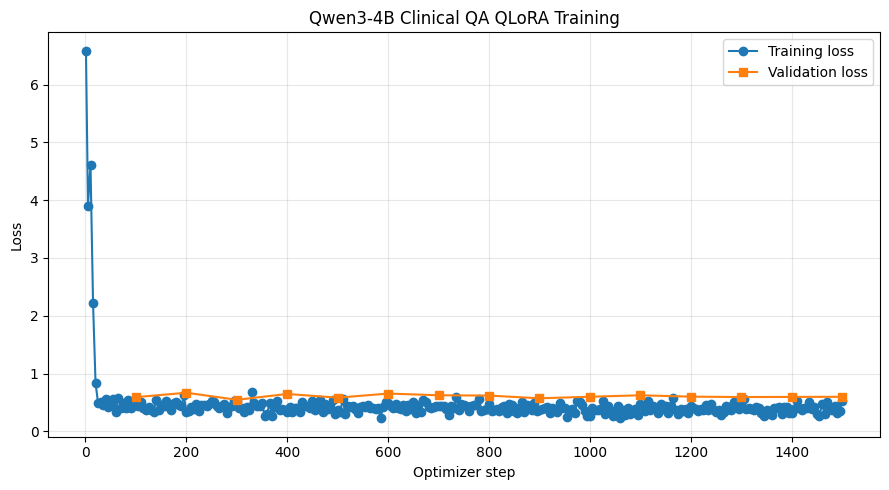

Training plot saved: /content/drive/MyDrive/clinical-qa-finetuning-v2/results/training/qwen3-medqa-pubmedqa-full_loss.png


In [20]:

# ============================================================
# Cell 19: Plot training and validation loss
# ============================================================

# Extract metrics logged by Hugging Face Trainer.
log_history = trainer.state.log_history

train_logs = [
    row for row in log_history
    if "loss" in row and "step" in row
]

eval_logs = [
    row for row in log_history
    if "eval_loss" in row and "step" in row
]

train_steps = [row["step"] for row in train_logs]
train_losses = [row["loss"] for row in train_logs]

eval_steps = [row["step"] for row in eval_logs]
eval_losses = [row["eval_loss"] for row in eval_logs]

fig, ax = plt.subplots(figsize=(9, 5))

if train_steps:
    ax.plot(
        train_steps,
        train_losses,
        marker="o",
        label="Training loss"
    )

if eval_steps:
    ax.plot(
        eval_steps,
        eval_losses,
        marker="s",
        label="Validation loss"
    )

ax.set_title("Qwen3-4B Clinical QA QLoRA Training")
ax.set_xlabel("Optimizer step")
ax.set_ylabel("Loss")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

# Save the figure for the GitHub README.
plot_path = RESULTS_DIR / f"{RUN_NAME}_loss.png"

plt.savefig(
    plot_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Training plot saved:", plot_path)


In [21]:

# ============================================================
# Cell 20: Collect reproducible training metrics
# ============================================================

training_metrics = {
    "experiment_name": RUN_NAME,
    "base_model": MODEL_ID,
    "training_mode": TRAIN_MODE,
    "training_examples": len(selected_train),
    "validation_examples": len(selected_val),
    "original_dataset_examples": len(train_dataset),
    "max_sequence_length": MAX_LENGTH,
    "training_loss": float(train_result.training_loss),
    "training_time_seconds": round(training_seconds, 2),
    "peak_allocated_gpu_gb": round(peak_memory_gb, 2),
    "learning_rate": 2e-4,
    "lora_rank": lora_config.r,
    "lora_alpha": lora_config.lora_alpha,
    "global_training_steps": trainer.state.global_step,
    "seed": SEED,
    "gpu": GPU_NAME,
    "pytorch_version": torch.__version__,
    "transformers_version": transformers.__version__,
    "trl_version": trl.__version__,
    "peft_version": peft.__version__,
}

# Store final validation loss if it was logged.
if eval_logs:
    training_metrics["final_validation_loss"] = float(
        eval_logs[-1]["eval_loss"]
    )

metrics_path = RESULTS_DIR / (
    f"{RUN_NAME}_metrics.json"
)

with open(metrics_path, "w", encoding="utf-8") as file:
    json.dump(training_metrics, file, indent=4)

print(json.dumps(training_metrics, indent=4))


{
    "experiment_name": "qwen3-medqa-pubmedqa-full",
    "base_model": "Qwen/Qwen3-4B",
    "training_mode": "full",
    "training_examples": 11999,
    "validation_examples": 64,
    "original_dataset_examples": 12000,
    "max_sequence_length": 1024,
    "training_loss": 0.4461868282953898,
    "training_time_seconds": 10178.72,
    "peak_allocated_gpu_gb": 4.53,
    "learning_rate": 0.0002,
    "lora_rank": 16,
    "lora_alpha": 32,
    "global_training_steps": 1500,
    "seed": 42,
    "gpu": "NVIDIA A100-SXM4-40GB",
    "pytorch_version": "2.14.1+cu130",
    "transformers_version": "4.57.6",
    "trl_version": "0.27.0",
    "peft_version": "0.18.1",
    "final_validation_loss": 0.5984628200531006
}


In [22]:

# ============================================================
# Cell 21: Save the trained LoRA adapter
# ============================================================

# Use separate directories for smoke and full experiments
# so that one run cannot overwrite another.
FINAL_ADAPTER_DIR = (
    MODEL_DIR / f"{RUN_NAME}-adapter"
)

FINAL_ADAPTER_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# The PEFT trainer saves trainable adapter weights
# and the configuration needed to reload them.
trainer.save_model(str(FINAL_ADAPTER_DIR))

# Save the tokenizer used for this experiment.
tokenizer.save_pretrained(
    str(FINAL_ADAPTER_DIR)
)

# Save training metrics alongside adapter artifacts.
shutil.copy2(
    metrics_path,
    FINAL_ADAPTER_DIR / "training_metrics.json"
)

# Confirm the essential adapter files exist.
assert (
    FINAL_ADAPTER_DIR / "adapter_config.json"
).exists()

assert (
    FINAL_ADAPTER_DIR / "adapter_model.safetensors"
).exists()

print("LoRA adapter saved successfully.")
print("Path:", FINAL_ADAPTER_DIR)


LoRA adapter saved successfully.
Path: /content/drive/MyDrive/clinical-qa-finetuning-v2/models/qwen3-medqa-pubmedqa-full-adapter


In [23]:

# ============================================================
# Cell 22: Save training history and run configuration
# ============================================================

logs_path = RESULTS_DIR / (
    f"{RUN_NAME}_training_logs.json"
)

with open(logs_path, "w", encoding="utf-8") as file:
    json.dump(
        trainer.state.log_history,
        file,
        indent=4
    )

config_path = RESULTS_DIR / (
    f"{RUN_NAME}_training_config.json"
)

with open(config_path, "w", encoding="utf-8") as file:
    json.dump(
        training_args.to_dict(),
        file,
        indent=4,
        default=str
    )

# Copy intermediate optimizer checkpoints to Drive.
# This is useful for recovery, but can consume Drive space.
CHECKPOINT_BACKUP_DIR = (
    MODEL_DIR / f"{RUN_NAME}-checkpoints"
)

CHECKPOINT_BACKUP_DIR.mkdir(
    parents=True,
    exist_ok=True
)

for checkpoint in OUTPUT_DIR.glob("checkpoint-*"):
    shutil.copytree(
        checkpoint,
        CHECKPOINT_BACKUP_DIR / checkpoint.name,
        dirs_exist_ok=True
    )

print("Training logs and checkpoints backed up.")


Training logs and checkpoints backed up.


In [24]:

# ============================================================
# Cell 23: Switch the fine-tuned model to inference mode
# ============================================================

finetuned_model = trainer.model

# Disable gradient computation and checkpointing.
finetuned_model.eval()
finetuned_model.gradient_checkpointing_disable()

# KV cache can be enabled during inference.
finetuned_model.config.use_cache = True

print("Fine-tuned model ready for inference.")


Fine-tuned model ready for inference.


In [25]:

# ============================================================
# Cell 24: Predict answers using the fine-tuned model
# ============================================================

import re


def parse_clinical_answer(response, task):
    """
    Extract a valid answer from a generated model response.

    Parameters
    ----------
    response : str
        Decoded text generated by the model.
    task : str
        Either 'medqa' or 'pubmedqa'.

    Returns
    -------
    str or None
        Predicted answer label, or None if no valid
        answer can be extracted.
    """

    response = response.strip()

    # Remove completed thinking blocks if present.
    response = re.sub(
        r"<think>.*?</think>",
        "",
        response,
        flags=re.DOTALL | re.IGNORECASE
    ).strip()

    if "<think>" in response.lower():
        return None

    if task == "medqa":
        match = re.search(
            r"^\s*\(?([ABCD])\)?(?:[.):]|\s|$)",
            response,
            re.IGNORECASE
        )

    elif task == "pubmedqa":
        match = re.search(
            r"^\s*(?:answer\s*:\s*)?(yes|no|maybe)\b",
            response,
            re.IGNORECASE
        )

    else:
        raise ValueError(f"Unknown task: {task}")

    return (
        match.group(1).upper()
        if match and task == "medqa"
        else match.group(1).lower()
        if match
        else None
    )


def predict_finetuned(example, max_new_tokens=24):
    """
    Generate a clinical QA answer using the fine-tuned model.

    Parameters
    ----------
    example : dict
        A normalized validation example containing the
        clinical question, task and expected answer.
    max_new_tokens : int
        Maximum number of generated tokens.

    Returns
    -------
    dict
        Prediction, raw model response and ground truth.
    """

    # Create the identical prompt format used in training.
    formatted = format_validation_record(example)

    prompt = formatted["prompt"]

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        add_special_tokens=False
    ).to("cuda")

    if inputs["input_ids"].shape[-1] + max_new_tokens > 2048:
        raise ValueError(
            "Validation question exceeds inference context."
        )

    with torch.inference_mode():
        generated = finetuned_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    # Decode only the tokens generated after the prompt.
    new_tokens = generated[0][
        inputs["input_ids"].shape[-1]:
    ]

    raw_response = tokenizer.decode(
        new_tokens,
        skip_special_tokens=True
    ).strip()

    prediction = parse_clinical_answer(
        raw_response,
        example["task"]
    )

    return {
        "task": example["task"],
        "prediction": prediction,
        "expected": example["answer"],
        "raw_response": raw_response,
        "correct": prediction == example["answer"]
    }


In [26]:

# ============================================================
# Cell 25: Run two example predictions
# ============================================================

# Use validation records, never training or final test rows.
examples = [
    medqa_val_dataset[0],
    pubmedqa_val_dataset[0]
]

for example in examples:
    result = predict_finetuned(example)

    print("\n" + "=" * 60)
    print("TASK:", result["task"])
    print("QUESTION:", example["question"][:200])

    print("EXPECTED:", result["expected"])
    print("PREDICTED:", result["prediction"])
    print("RAW RESPONSE:", repr(result["raw_response"]))
    print("CORRECT:", result["correct"])


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



TASK: medqa
QUESTION: A 35-year-old woman comes to your office with a variety of complaints. As part of her evaluation, she undergoes laboratory testing which reveals the presence of anti-centromere antibodies. All of the 
EXPECTED: C
PREDICTED: A
RAW RESPONSE: 'A'
CORRECT: False

TASK: pubmedqa
QUESTION: Can tailored interventions increase mammography use among HMO women?
EXPECTED: yes
PREDICTED: yes
RAW RESPONSE: 'yes'
CORRECT: True


In [27]:

# ============================================================
# Cell 26: Verify training outputs and artifacts
# ============================================================

def verify_training_outputs(adapter_directory, results_directory):
    """
    Check that the required QLoRA artifacts were saved.

    Parameters
    ----------
    adapter_directory : Path
        Directory containing the trained LoRA adapter.
    results_directory : Path
        Directory containing experiment metrics and logs.

    Returns
    -------
    bool
        True if all required artifacts exist.
    """

    required_files = [
        adapter_directory / "adapter_config.json",
        adapter_directory / "adapter_model.safetensors",
        adapter_directory / "training_metrics.json",
        results_directory / f"{RUN_NAME}_training_logs.json",
        results_directory / f"{RUN_NAME}_loss.png",
    ]

    missing_files = [
        str(path)
        for path in required_files
        if not path.exists()
    ]

    if missing_files:
        print("Missing artifacts:")
        for file in missing_files:
            print("-", file)
        return False

    print("All required QLoRA artifacts are present.")
    return True


training_verified = verify_training_outputs(
    FINAL_ADAPTER_DIR,
    RESULTS_DIR
)

assert training_verified, "Training artifacts incomplete."


All required QLoRA artifacts are present.


In [28]:

# Verify whether training actually completed.

print("Current global step:", trainer.state.global_step)
print("Configured max steps:", training_args.max_steps)

# Find training and evaluation loss entries.
training_logs = [
    log for log in trainer.state.log_history
    if "loss" in log and "step" in log
]

validation_logs = [
    log for log in trainer.state.log_history
    if "eval_loss" in log
]

print("\nTraining loss records:", len(training_logs))
print("Validation loss records:", len(validation_logs))

if training_logs:
    print("Latest training loss:", training_logs[-1]["loss"])
else:
    print("No training loss recorded yet.")

if validation_logs:
    print("Latest validation loss:", validation_logs[-1]["eval_loss"])
else:
    print("No validation loss recorded yet.")


Current global step: 1500
Configured max steps: -1

Training loss records: 301
Validation loss records: 15
Latest training loss: 0.5255
Latest validation loss: 0.5984628200531006


In [29]:

# ============================================================
# Cell 27: Evaluate fine-tuned Qwen3-4B on both datasets
# ============================================================

from tqdm.auto import tqdm
import pandas as pd


def evaluate_finetuned_task(dataset, task_name, n=50):
    """
    Evaluate the fine-tuned model on validation questions.

    Parameters
    ----------
    dataset : Dataset
        Normalized validation dataset.
    task_name : str
        Human-readable task name.
    n : int
        Maximum number of questions to evaluate.

    Returns
    -------
    tuple
        DataFrame of predictions and accuracy metrics.
    """

    # Select a reproducible validation subset.
    subset = dataset.shuffle(seed=SEED).select(
        range(min(n, len(dataset)))
    )

    predictions = []

    for example in tqdm(subset, desc=task_name):
        # Run inference with the fine-tuned LoRA model.
        result = predict_finetuned(example)

        predictions.append({
            "id": example["id"],
            "task": example["task"],
            "expected": result["expected"],
            "predicted": result["prediction"],
            "correct": result["correct"],
            "raw_response": result["raw_response"]
        })

    df = pd.DataFrame(predictions)

    metrics = {
        "task": task_name,
        "samples": len(df),
        "accuracy": float(df["correct"].mean()),
        "valid_answer_rate": float(
            df["predicted"].notna().mean()
        )
    }

    return df, metrics


medqa_ft_df, medqa_ft_metrics = evaluate_finetuned_task(
    medqa_val_dataset,
    "MedQA",
    n=50
)

pubmed_ft_df, pubmed_ft_metrics = evaluate_finetuned_task(
    pubmedqa_val_dataset,
    "PubMedQA",
    n=50
)

print("\nFine-tuned MedQA:", medqa_ft_metrics)
print("Fine-tuned PubMedQA:", pubmed_ft_metrics)


MedQA:   0%|          | 0/50 [00:00<?, ?it/s]

PubMedQA:   0%|          | 0/50 [00:00<?, ?it/s]


Fine-tuned MedQA: {'task': 'MedQA', 'samples': 50, 'accuracy': 0.7, 'valid_answer_rate': 1.0}
Fine-tuned PubMedQA: {'task': 'PubMedQA', 'samples': 50, 'accuracy': 0.74, 'valid_answer_rate': 1.0}
